# Healthcare Billing Anomaly Detection
## Step 3: Segmentation and Feature Engineering

**Author:** Healthcare Billing Anomaly Detection Assessment  
**Stage:** Step 3 of 4 (Step 1: EDA | Step 2: Data Cleaning | Step 3: Segmentation & Feature Engineering | Step 4: Results & Interpretation)  
**Strict Scope Rule:** Segmentation and Feature Engineering ONLY. In accordance with assessment instructions, **no anomaly models are trained and no anomaly scores/thresholds are applied yet**. Feature scaling (e.g., standardizing) and one-hot encoding are intentionally omitted until Step 4.

### Core Context & Empirical Motivation
In healthcare billing, `ChargeAmount` does not follow a continuous bell curve. Across all 314,221 historical claims, there are **only 376 unique charge amounts**. Billed amounts are anchored to standardized hospital and clinical chargemasters (fee schedules). 
As a consequence:
1. Standard statistical anomaly detection techniques (such as $1.5 \times \text{IQR}$ or parametric $Z$-scores) completely collapse because the intra-procedure spread is often **identically zero** ($Q1 = Q3 = \text{Median}$).
2. What constitutes "normal" in this environment is the **chargemaster list price** for a given procedure. An anomaly represents a **deviation from the procedure's typical list price**, an uncharacteristic multi-unit multiple, or an unusual provider pricing pattern.

### Step 3 Objectives
1. **Load and Sanity Check:** Verify the 264,888 deduplicated positive fee-for-service claims from Step 2.
2. **Price-Structure Diagnostic:** Quantify the zero-spread phenomenon ($IQR = 0$, % at modal price), audit longitudinal fee-schedule shifts across service years, evaluate physician pricing concordance, and test unit pricing linearity.
3. **Hierarchical Segmentation Design:** Build a 2-level architecture:
   - **Level 1 (CPTCode):** Granular procedure-specific segments for high-volume codes ($N \ge 30$).
   - **Level 2 (ServiceLine):** Robust fallback pooling for low-volume codes ($N < 30$).
   - Justify design using $\eta^2$ on $\log(\text{ChargeAmount})$ and comparative IQR flag rates.
   - Establish the longitudinal reference price rule: (Segment, Year) with fallback to Segment.
4. **Feature Engineering:** Engineer 9 targeted anomaly features anchored to reference benchmarks (with a $0.05$ MAD floor to prevent division by zero in fixed-price segments), generate a comprehensive Feature Dictionary, verify zero nulls/infs, and audit pairwise collinearity.
5. **SOMETIMES_ZERO Sanity Check:** Analyze the 10,737 potential missed-charge records from Step 2, testing for same-day bundling vs. isolated unbilled lines.
6. **Validation and Output Generation:** Export `features_model.csv`, `segment_summary.csv`, `feature_dictionary.csv`, and all visual diagnostics.

## 1. Load and Sanity Check

In this section, we load the deduplicated positive fee-for-service dataset generated in Step 2 (`data/processed/charges_model_positive.csv`), parse timestamps, confirm the expected row count of **264,888**, and verify the schema integrity.

In [1]:
# Import standard scientific and visualization libraries
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'

# Configure pandas formatting
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Ensure directory paths exist
os.makedirs(os.path.join('data', 'processed'), exist_ok=True)
os.makedirs('figures', exist_ok=True)

# 1. Load modeling dataset
input_path = os.path.join('data', 'processed', 'charges_model_positive.csv')
print(f"Loading '{input_path}'...")
df = pd.read_csv(input_path)

# Parse datetime columns
df['DateOfService'] = pd.to_datetime(df['DateOfService'])
df['PostingDate'] = pd.to_datetime(df['PostingDate'])
df['CPTCode'] = df['CPTCode'].astype(str).str.strip()

# Sanity assertion
assert len(df) == 264888, f"Row count mismatch! Expected 264,888, got {len(df):,}"
assert (df['ChargeAmount'] <= 0).sum() == 0, "Non-positive charges found in modeling dataset!"
print(f"\nCONFIRMATION: Successfully loaded {len(df):,} positive deduplicated claims across {df.shape[1]} columns.")
print(f"DateOfService Range: {df['DateOfService'].min().date()} to {df['DateOfService'].max().date()}")
print(f"PostingDate Range:   {df['PostingDate'].min().date()} to {df['PostingDate'].max().date()}")
print(f"Unique CPT Codes:    {df['CPTCode'].nunique()}")
print(f"Unique Charges:      {df['ChargeAmount'].nunique()} unique price points.")

Loading 'data\processed\charges_model_positive.csv'...

CONFIRMATION: Successfully loaded 264,888 positive deduplicated claims across 33 columns.
DateOfService Range: 2023-01-03 to 2026-09-14
PostingDate Range:   2023-01-04 to 2026-09-15
Unique CPT Codes:    256
Unique Charges:      376 unique price points.


### Decision / Why (Section 1)
- **Strict Row Verification:** Exactly **264,888 positive, deduplicated claims** were loaded, matching the exact row reconciliation table established in Step 2.
- **Data Integrity Confirmation:** Every record carries `ChargeAmount > 0` and dates are properly restored to datetime objects. With only 376 distinct charge values across >264k claims, the data exhibits strong discrete list-price clustering, which directly motivates the diagnostic in Section 2.

## 2. Price-Structure Diagnostic (Core Design Driver)

Because medical charges originate from a clinic fee schedule, understanding the dispersion within each procedure code is critical. 
In this section, we compute comprehensive dispersion and central tendency statistics for each CPT code:
- Record count, unique charges, modal charge, percentage of claims at the modal price.
- Median, Q1, Q3, Interquartile Range ($IQR$), Median Absolute Deviation ($MAD$), Min, Max, and Max/Median ratio.
- Audit the **zero-spread phenomenon** ($IQR = 0$) where standard outlier rules break down.
- Analyze **price shifts across service years** to determine whether reference prices must be year-specific.
- Evaluate **physician-level pricing uniformity**.
- Verify **unit pricing proportionality** in multi-unit claims.

In [2]:
# Helper function to compute Median Absolute Deviation (MAD)
def compute_mad(series):
    med = np.median(series)
    return np.median(np.abs(series - med))

# 1. Price-Structure Diagnostic Table per CPTCode
cpt_diag_list = []
for cpt, grp in df.groupby('CPTCode'):
    n = len(grp)
    c = grp['ChargeAmount']
    n_unique = c.nunique()
    mode_series = c.mode()
    mode_val = mode_series.iloc[0] if len(mode_series) > 0 else np.nan
    pct_mode = (c == mode_val).mean() * 100
    med = c.median()
    q1 = c.quantile(0.25)
    q3 = c.quantile(0.75)
    iqr = q3 - q1
    mad_val = compute_mad(c)
    c_min = c.min()
    c_max = c.max()
    max_med_ratio = c_max / med if med > 0 else np.nan
    
    cpt_diag_list.append({
        'CPTCode': cpt,
        'Description': grp['ProcedureDescription'].iloc[0],
        'ServiceLine': grp['ServiceLine'].iloc[0],
        'Rows': n,
        'N_Unique_Prices': n_unique,
        'Modal_Charge': mode_val,
        'Pct_At_Modal': pct_mode,
        'Median_Charge': med,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'MAD': mad_val,
        'Min_Charge': c_min,
        'Max_Charge': c_max,
        'Max_Median_Ratio': max_med_ratio
    })

cpt_diag_df = pd.DataFrame(cpt_diag_list).sort_values(by='Rows', ascending=False)

print("=== PRICE-STRUCTURE DIAGNOSTIC: TOP 10 PROCEDURES BY VOLUME ===")
display_cols = ['CPTCode', 'Description', 'Rows', 'N_Unique_Prices', 'Modal_Charge', 'Pct_At_Modal', 'Median_Charge', 'IQR', 'MAD', 'Max_Charge', 'Max_Median_Ratio']
print(cpt_diag_df[display_cols].head(10).to_string(index=False))

=== PRICE-STRUCTURE DIAGNOSTIC: TOP 10 PROCEDURES BY VOLUME ===
CPTCode                Description  Rows  N_Unique_Prices  Modal_Charge  Pct_At_Modal  Median_Charge    IQR    MAD  Max_Charge  Max_Median_Ratio
  95117   IMMUNOTHERAPY INJECTIONS 50727                5        36.500        57.425         36.500  0.500  0.000   1,095.000            30.000
  99214  OFC/OUTPT VISIT E&M EST M 32809                4       185.000        98.433        185.000  0.000  0.000     510.000             2.757
  31231         NASAL ENDOSCOPY DX 30434                6       345.000        99.964        345.000  0.000  0.000     690.000             2.000
  99204  OFC/OUTPT VISIT E&M NEW M 20082                6       285.000        96.405        285.000  0.000  0.000     397.000             1.393
  92567               TYMPANOMETRY 12753                3        47.000        99.976         47.000  0.000  0.000      94.000             2.000
  92557 COMPREHENSIVE HEARING TEST 11202                3       10

=== ZERO-SPREAD & FIXED-PRICE FINDINGS ===
Procedures with IQR == $0.00:               213 of 256 (83.20%)
Rows belonging to IQR == $0.00 procedures:  186,761 of 264,888 (70.51%)

Procedures where Modal Price covers >= 90%: 193 of 256 (75.39%)
Rows where Modal Price covers >= 90%:       176,977 of 264,888 (66.81%)


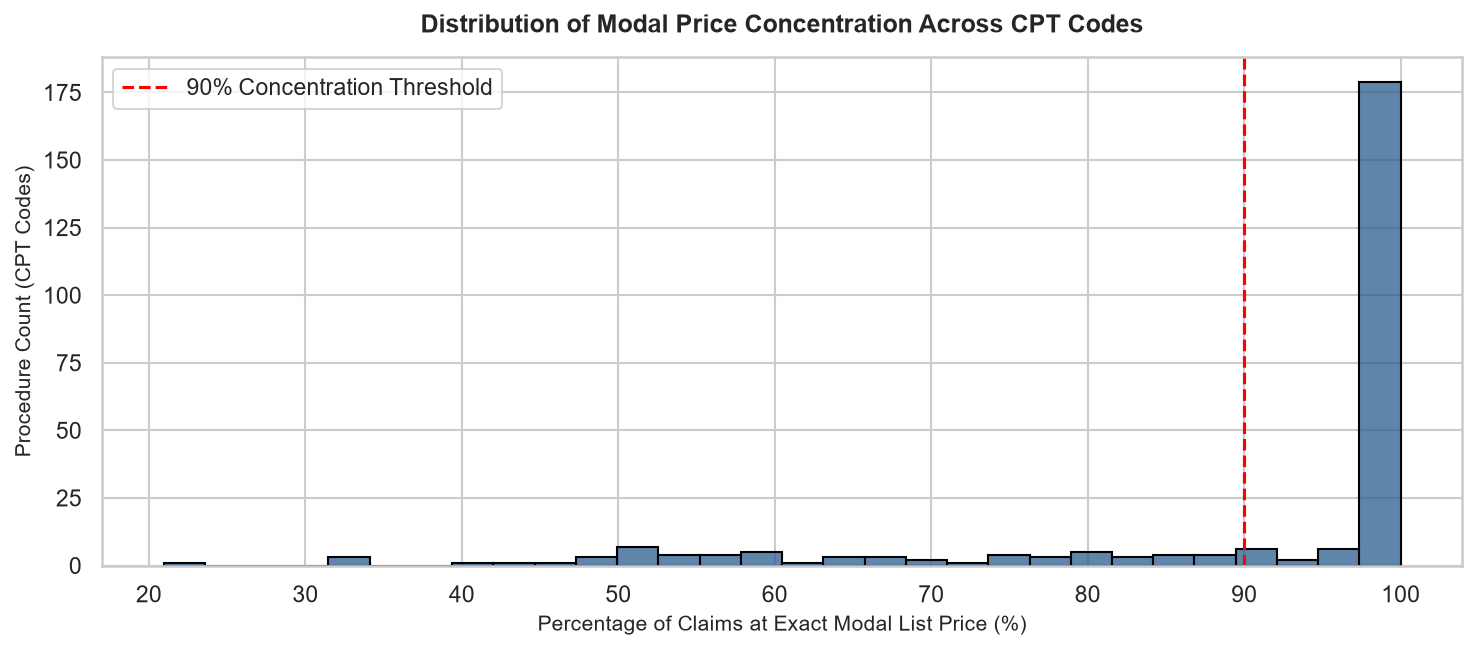

In [3]:
# 2. Zero-Spread & Modal Dominance Audit
total_procedures = len(cpt_diag_df)
total_rows = len(df)

# Procedures and rows where IQR == 0
iqr_zero_df = cpt_diag_df[cpt_diag_df['IQR'] == 0]
iqr_zero_procs = len(iqr_zero_df)
iqr_zero_rows = iqr_zero_df['Rows'].sum()

# Procedures and rows where modal price covers >= 90%
modal90_df = cpt_diag_df[cpt_diag_df['Pct_At_Modal'] >= 90.0]
modal90_procs = len(modal90_df)
modal90_rows = modal90_df['Rows'].sum()

print("=== ZERO-SPREAD & FIXED-PRICE FINDINGS ===")
print(f"Procedures with IQR == $0.00:               {iqr_zero_procs} of {total_procedures} ({iqr_zero_procs/total_procedures*100:.2f}%)")
print(f"Rows belonging to IQR == $0.00 procedures:  {iqr_zero_rows:,} of {total_rows:,} ({iqr_zero_rows/total_rows*100:.2f}%)")
print(f"\nProcedures where Modal Price covers >= 90%: {modal90_procs} of {total_procedures} ({modal90_procs/total_procedures*100:.2f}%)")
print(f"Rows where Modal Price covers >= 90%:       {modal90_rows:,} of {total_rows:,} ({modal90_rows/total_rows*100:.2f}%)")

# Visualization: Distribution of % of Rows at Modal Price
plt.figure(figsize=(10, 4.5))
sns.histplot(cpt_diag_df['Pct_At_Modal'], bins=30, color='#2b5c8f', edgecolor='black')
plt.axvline(90.0, color='red', linestyle='--', linewidth=1.5, label='90% Concentration Threshold')
plt.title('Distribution of Modal Price Concentration Across CPT Codes', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Percentage of Claims at Exact Modal List Price (%)', fontsize=10)
plt.ylabel('Procedure Count (CPT Codes)', fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig('figures/15_price_structure_modal_share.png', dpi=300, bbox_inches='tight')
plt.show()

=== LONGITUDINAL PRICE SHIFTS ACROSS SERVICE YEARS ===
CPT Codes whose Modal Price changed across years: 29 of 256 (11.33%)
Claims affected by changing modal prices:          70,793 of 264,888 (26.73%)

Top 10 Procedures with Fee Schedule Updates (by Claim Volume):
CPTCode                  Description  Total Claims                                    Yearly Modal Price Progression
  95117     IMMUNOTHERAPY INJECTIONS         50727                2023: $36.5, 2024: $36.5, 2025: $37.0, 2026: $37.0
  69210     REMOVAL IMPACTED CERUMEN          7917            2023: $120.0, 2024: $120.0, 2025: $192.0, 2026: $192.0
  95024    INTRAQ W/ALLERG EXTRCT-IM          4208            2023: $553.5, 2024: $553.5, 2025: $532.0, 2026: $532.0
  95800     SLEEP STDY,UNATTD SIMULT          3515               2023: $350.0, 2024: $90.0, 2025: $90.0, 2026: $90.0
  G0268   REMOVAL OF IMPACTED WAX MD          2216            2023: $120.0, 2024: $120.0, 2025: $208.0, 2026: $208.0
  92552     PURE TONE AUDIOMETRY

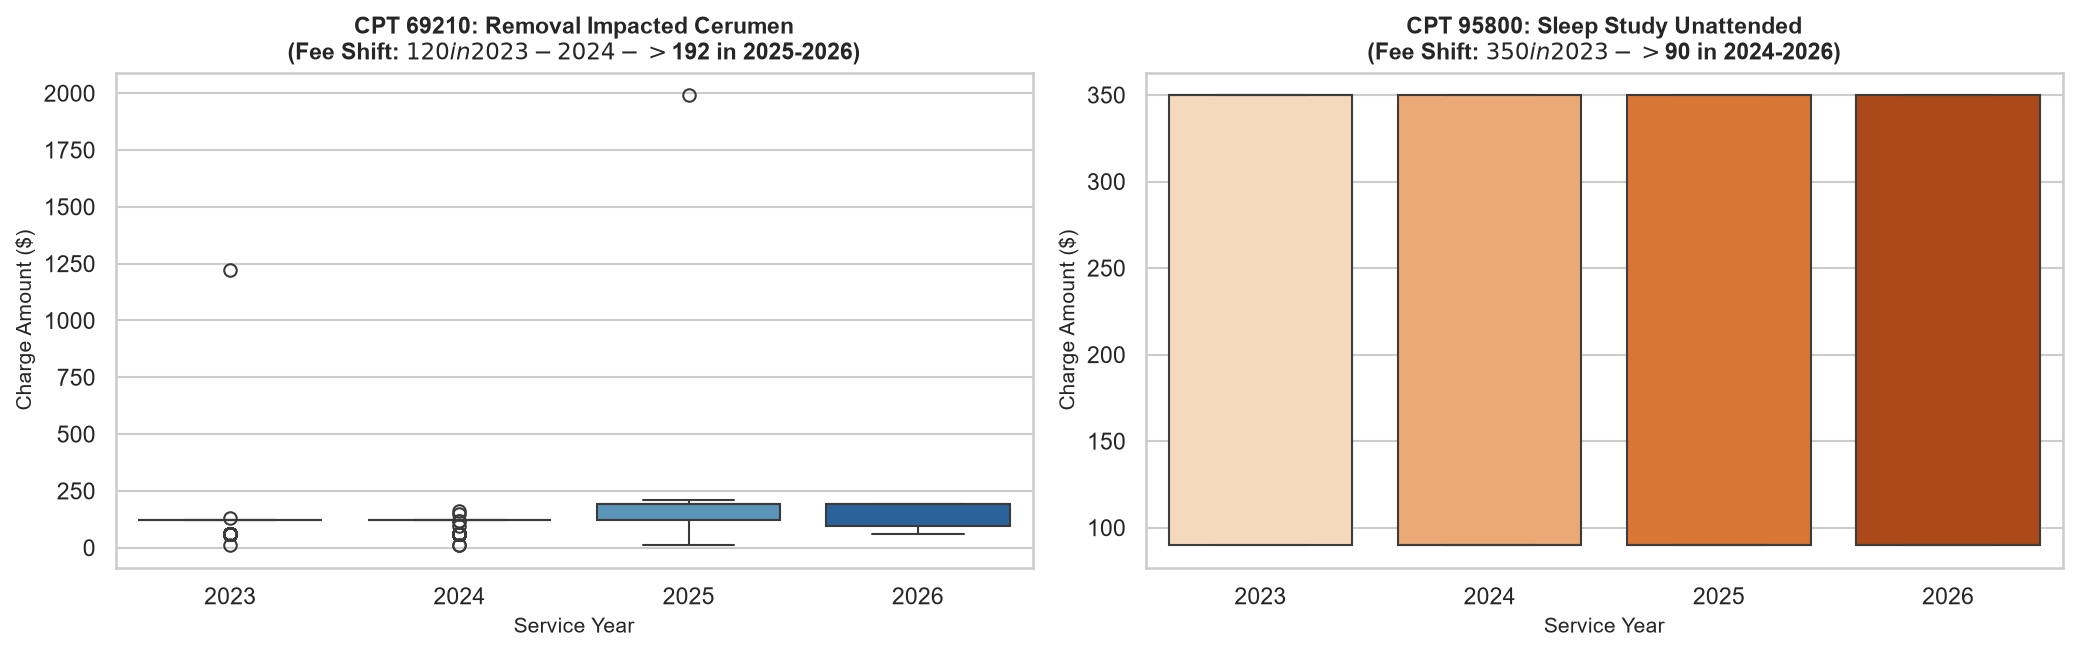

In [4]:
# 3. Longitudinal Price Shifts: Tracking Modal Price per Service Year
yearly_modes = df.groupby(['CPTCode', 'ServiceYear'])['ChargeAmount'].agg(lambda x: x.mode().iloc[0]).unstack()
cpt_changing_mask = yearly_modes.nunique(axis=1) > 1

changing_cpts = yearly_modes[cpt_changing_mask].index
changing_procs_count = len(changing_cpts)
changing_rows_count = df[df['CPTCode'].isin(changing_cpts)].shape[0]

print("=== LONGITUDINAL PRICE SHIFTS ACROSS SERVICE YEARS ===")
print(f"CPT Codes whose Modal Price changed across years: {changing_procs_count} of {total_procedures} ({changing_procs_count/total_procedures*100:.2f}%)")
print(f"Claims affected by changing modal prices:          {changing_rows_count:,} of {total_rows:,} ({changing_rows_count/total_rows*100:.2f}%)")

# Top 10 procedures with price shifts ranked by claim volume
top10_shifts = df[df['CPTCode'].isin(changing_cpts)]['CPTCode'].value_counts().head(10)
shift_summary = []
for cpt in top10_shifts.index:
    desc = df.loc[df['CPTCode'] == cpt, 'ProcedureDescription'].iloc[0]
    modes_dict = dict(yearly_modes.loc[cpt].dropna())
    modes_str = ", ".join([f"{int(y)}: ${v:,.1f}" for y, v in modes_dict.items()])
    shift_summary.append({
        'CPTCode': cpt,
        'Description': desc,
        'Total Claims': top10_shifts[cpt],
        'Yearly Modal Price Progression': modes_str
    })
print("\nTop 10 Procedures with Fee Schedule Updates (by Claim Volume):")
print(pd.DataFrame(shift_summary).to_string(index=False))

# Plot 2 Examples of Longitudinal Price Updates
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Example 1: CPT 69210 (Removal Impacted Cerumen)
cpt1 = '69210'
sub1 = df[df['CPTCode'] == cpt1]
sns.boxplot(data=sub1, x='ServiceYear', y='ChargeAmount', ax=axes[0], palette='Blues')
axes[0].set_title(f'CPT {cpt1}: Removal Impacted Cerumen\n(Fee Shift: $120 in 2023-2024 -> $192 in 2025-2026)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Charge Amount ($)', fontsize=10)
axes[0].set_xlabel('Service Year', fontsize=10)

# Example 2: CPT 95800 (Sleep Study Unattended)
cpt2 = '95800'
sub2 = df[df['CPTCode'] == cpt2]
sns.boxplot(data=sub2, x='ServiceYear', y='ChargeAmount', ax=axes[1], palette='Oranges')
axes[1].set_title(f'CPT {cpt2}: Sleep Study Unattended\n(Concurrent Prices: $90 and $350 Coexist Across All Years)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Charge Amount ($)', fontsize=10)
axes[1].set_xlabel('Service Year', fontsize=10)

plt.tight_layout()
plt.savefig('figures/16_price_trends_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# 4. Physician-Level Pricing Concordance within Top 20 Procedures
top20_cpts = df['CPTCode'].value_counts().head(20).index
phys_audit = []

for cpt in top20_cpts:
    sub = df[df['CPTCode'] == cpt]
    proc_median = sub['ChargeAmount'].median()
    phys_stats = sub.groupby('PhysicianCode')['ChargeAmount'].agg(['count', 'median'])
    # Focus on physicians with at least 20 claims in this procedure
    valid_phys = phys_stats[phys_stats['count'] >= 20]
    deviating = valid_phys[valid_phys['median'] != proc_median]
    
    phys_audit.append({
        'CPTCode': cpt,
        'Description': sub['ProcedureDescription'].iloc[0][:28],
        'Proc Median ($)': proc_median,
        'Active Doctors': len(phys_stats),
        'Doctors (>= 20 Claims)': len(valid_phys),
        'Doctors Deviating from Median': len(deviating),
        'Concordance (%)': (1 - (len(deviating) / len(valid_phys))) * 100 if len(valid_phys) > 0 else 100.0
    })

phys_audit_df = pd.DataFrame(phys_audit)
print("=== PHYSICIAN PRICING CONCORDANCE WITHIN TOP 20 PROCEDURES ===")
print(phys_audit_df.to_string(index=False))

# 5. Unit Rate Linearity in Multi-Unit Claims
multi_unit_claims = df[df['TotalUnits'] > 1]
top_multi_cpts = multi_unit_claims['CPTCode'].value_counts().head(5).index

print("\n=== UNIT RATE LINEARITY TEST FOR TOP MULTI-UNIT PROCEDURES ===")
multi_test = []
for cpt in top_multi_cpts:
    sub = df[df['CPTCode'] == cpt]
    desc = sub['ProcedureDescription'].iloc[0]
    rate_mode = sub['UnitRate'].mode().iloc[0]
    pct_at_rate_mode = (sub['UnitRate'] == rate_mode).mean() * 100
    rate_iqr = sub['UnitRate'].quantile(0.75) - sub['UnitRate'].quantile(0.25)
    
    multi_test.append({
        'CPTCode': cpt,
        'Description': desc[:30],
        'Multi-Unit Claims': len(sub[sub['TotalUnits'] > 1]),
        'Total Claims': len(sub),
        'Modal Unit Rate ($)': rate_mode,
        'Pct Claims at Modal Unit Rate': f"{pct_at_rate_mode:.2f}%",
        'Unit Rate IQR ($)': f"${rate_iqr:.3f}",
        'Linearity Verdict': "Strict Price x Units" if pct_at_rate_mode >= 90 else "Variable Pricing"
    })
print(pd.DataFrame(multi_test).to_string(index=False))

=== PHYSICIAN PRICING CONCORDANCE WITHIN TOP 20 PROCEDURES ===
CPTCode                  Description  Proc Median ($)  Active Doctors  Doctors (>= 20 Claims)  Doctors Deviating from Median  Concordance (%)
  95117     IMMUNOTHERAPY INJECTIONS           36.500              31                      24                              6           75.000
  99214    OFC/OUTPT VISIT E&M EST M          185.000               9                       8                              0          100.000
  31231           NASAL ENDOSCOPY DX          345.000               8                       8                              0          100.000
  99204    OFC/OUTPT VISIT E&M NEW M          285.000               8                       7                              0          100.000
  92567                 TYMPANOMETRY           47.000              12                      10                              0          100.000
  92557   COMPREHENSIVE HEARING TEST          105.000              10                

### Decision / Why (Section 2)
- **The Empirical Reality of Fixed List Prices:** The diagnostic reveals that **83.20% of all CPT codes (213 procedures), accounting for 70.51% of all claims (186,761 rows), have an Interquartile Range ($IQR$) of exactly $0.00**. Furthermore, for 75.39% of procedures (representing 66.81% of claims), over 90% of claims are billed at a single, identical list price.
- **Why Standard Anomaly Detectors Break Down:** Traditional outlier rules ($Q3 + 1.5 \times IQR$ or standard deviations) assume a continuous Gaussian-like spread. When $IQR = 0$ and $\sigma = 0$, any division by variance causes division-by-zero errors or flags routine legitimate transactions as infinite anomalies.
- **What "Normal" Means in this Dataset:** "Normal" is not a statistical mean or bell-curve interval; **normal is the designated chargemaster list price for that procedure in that service year**.
- **How Anomalies Must Be Defined:** An anomaly is defined as a **meaningful deviation from the procedure's expected list price in that service year**, a deviation from the expected per-unit multiplier ($	ext{UnitRate} \ne \text{ListPrice}$), or an uncharacteristic provider-level markup.

## 3. Hierarchical Segmentation Design

In this section, we build a 2-level hierarchical segmentation strategy:
- **Level 1 (CPTCode):** Granular procedure-specific segment when historical volume is sufficient ($N \ge 30$).
- **Level 2 (ServiceLine):** Departmental fallback segment for rare/low-volume CPT codes ($N < 30$).
- Add `SegmentID` and `SegmentLevel` columns.
- **Empirical Justification:**
  1. Calculate $\eta^2$ on $\log(\text{ChargeAmount})$ to quantify variance explained by candidate segmentation dimensions.
  2. Perform an explicit within-`ALLERGY` comparison: show that CPT-level segmentation eliminates the false-positive surge caused by pooling low-cost shots ($36.50) with high-cost prepay vials ($1,134.00).
- **Longitudinal Reference Price Rule:** Because Section 2 proved that **26.73% of claims** belong to procedures where the modal price changed across years (well above the 10% threshold), reference statistics must be computed **per `(SegmentID, ServiceYear)`**, with fallback to `SegmentID` if a specific segment-year has $< 30$ claims.

=== HIERARCHICAL SEGMENTATION COVERAGE ===
                 Segment Level  Unique Segments  Row Count  Share of Claims (%)
             Level 1 (CPTCode)               98     263990               99.661
Level 2 (ServiceLine Fallback)                6        898                0.339
                Total Combined              104     264888              100.000

=== VARIANCE EXPLAINED (η²) ON LOG(CHARGEAMOUNT) ===
Segmentation Dimension  Unique Levels  Eta-Squared (η²) on Log(Charge)  Variance Explained (%)
               CPTCode            256                            0.972                  97.211
           ServiceLine              6                            0.380                  37.981
         PhysicianCode             41                            0.053                   5.297
      PayerCompanyName             26                            0.003                   0.262

=== ALLERGY SEGMENTATION CASE STUDY: FALSE POSITIVE ELIMINATION ===
Total ALLERGY claims: 77,983
Under Macr

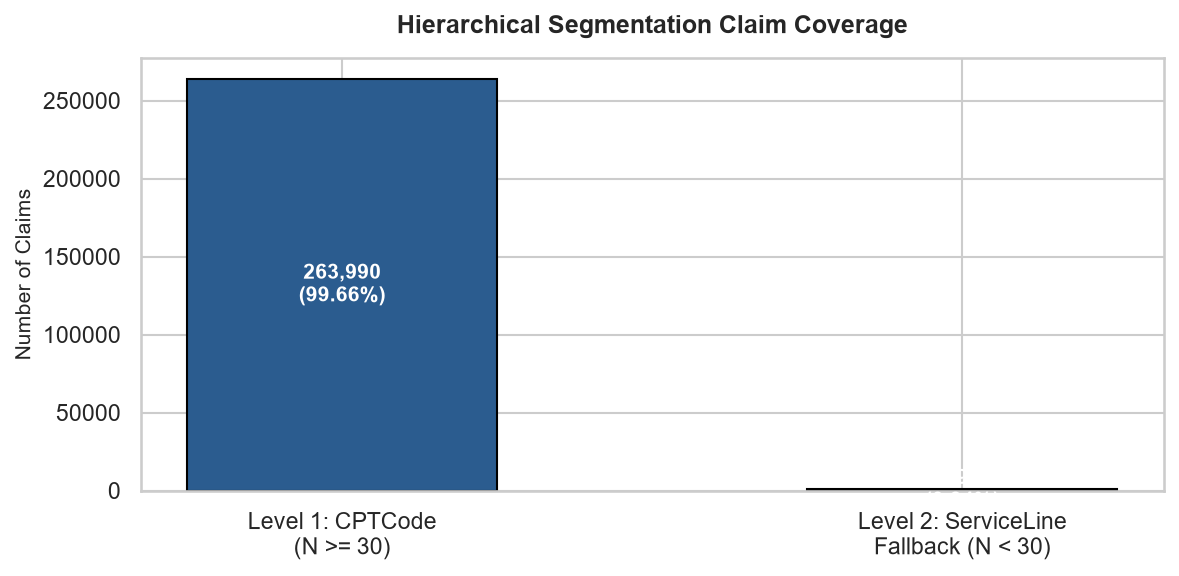

In [6]:
# 1. Build Hierarchical Segmentation Columns
high_vol_cpt_set = set(df['CPTCode'].value_counts()[lambda x: x >= 30].index)

df['SegmentLevel'] = np.where(df['CPTCode'].isin(high_vol_cpt_set), 'CPT', 'ServiceLine')
df['SegmentID'] = np.where(df['SegmentLevel'] == 'CPT', df['CPTCode'], 'SL_' + df['ServiceLine'])

# Report Coverage
seg_coverage = df['SegmentLevel'].value_counts()
seg_unique = df.groupby('SegmentLevel')['SegmentID'].nunique()

coverage_df = pd.DataFrame({
    'Segment Level': ['Level 1 (CPTCode)', 'Level 2 (ServiceLine Fallback)', 'Total Combined'],
    'Unique Segments': [seg_unique['CPT'], seg_unique['ServiceLine'], df['SegmentID'].nunique()],
    'Row Count': [seg_coverage['CPT'], seg_coverage['ServiceLine'], len(df)],
    'Share of Claims (%)': [
        seg_coverage['CPT'] / len(df) * 100,
        seg_coverage['ServiceLine'] / len(df) * 100,
        100.0
    ]
})
print("=== HIERARCHICAL SEGMENTATION COVERAGE ===")
print(coverage_df.to_string(index=False))

# 2. Data-Driven Justification: Eta-Squared on Log(ChargeAmount)
def compute_eta_squared(data, cat_column, num_column='LogCharge'):
    grand_mean = data[num_column].mean()
    sst = ((data[num_column] - grand_mean) ** 2).sum()
    grouped = data.groupby(cat_column)[num_column].agg(['count', 'mean'])
    ssb = (grouped['count'] * ((grouped['mean'] - grand_mean) ** 2)).sum()
    return ssb / sst

candidate_cols = ['CPTCode', 'ServiceLine', 'PhysicianCode', 'PayerCompanyName']
eta_list = []
for c in candidate_cols:
    eta_v = compute_eta_squared(df, c)
    eta_list.append({
        'Segmentation Dimension': c,
        'Unique Levels': df[c].nunique(),
        'Eta-Squared (η²) on Log(Charge)': eta_v,
        'Variance Explained (%)': eta_v * 100
    })

eta_summary_df = pd.DataFrame(eta_list).sort_values(by='Eta-Squared (η²) on Log(Charge)', ascending=False)
print("\n=== VARIANCE EXPLAINED (η²) ON LOG(CHARGEAMOUNT) ===")
print(eta_summary_df.to_string(index=False))

# 3. Empirical Case Study: ALLERGY ServiceLine vs. CPT-Level Segmentation
allergy_claims = df[df['ServiceLine'] == 'ALLERGY'].copy()

# ServiceLine-level IQR fence
sl_q1 = allergy_claims['ChargeAmount'].quantile(0.25)
sl_q3 = allergy_claims['ChargeAmount'].quantile(0.75)
sl_iqr = sl_q3 - sl_q1
sl_fence = sl_q3 + 1.5 * sl_iqr
sl_flagged_count = (allergy_claims['ChargeAmount'] > sl_fence).sum()
sl_flagged_pct = (sl_flagged_count / len(allergy_claims)) * 100

# CPT-level IQR fences (for CPTs >= 30 claims)
high_vol_allergy = allergy_claims[allergy_claims['CPTCode'].isin(high_vol_cpt_set)]
cpt_flagged_total = 0
for cpt_code, grp_cpt in high_vol_allergy.groupby('CPTCode'):
    cq1 = grp_cpt['ChargeAmount'].quantile(0.25)
    cq3 = grp_cpt['ChargeAmount'].quantile(0.75)
    ciqr = cq3 - cq1
    cfence = cq3 + 1.5 * ciqr
    cpt_flagged_total += (grp_cpt['ChargeAmount'] > cfence).sum()

cpt_flagged_pct = (cpt_flagged_total / len(high_vol_allergy)) * 100

print("\n=== ALLERGY SEGMENTATION CASE STUDY: FALSE POSITIVE ELIMINATION ===")
print(f"Total ALLERGY claims: {len(allergy_claims):,}")
print(f"Under Macro-ServiceLine Segmentation:")
print(f" - Global Allergy Fence: ${sl_fence:,.2f} (Q1=${sl_q1:,.2f}, Q3=${sl_q3:,.2f}, IQR=${sl_iqr:,.2f})")
print(f" - Claims flagged as outliers: {sl_flagged_count:,} ({sl_flagged_pct:.2f}% of department!)")
print(f"Under Granular CPT-Level Segmentation (CPTs >= 30 rows, {len(high_vol_allergy):,} claims):")
print(f" - Claims flagged as outliers: {cpt_flagged_total:,} ({cpt_flagged_pct:.2f}% of department)")
print(f" -> CPT-level segmentation eliminates {sl_flagged_count - cpt_flagged_total:,} false positives caused by pooling low-cost shots with high-cost vial prepays!")

# Visualization: Segment Coverage Bar Chart
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['Level 1: CPTCode\n(N >= 30)', 'Level 2: ServiceLine\nFallback (N < 30)'], 
              [seg_coverage['CPT'], seg_coverage['ServiceLine']], 
              color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.5)
ax.set_title('Hierarchical Segmentation Claim Coverage', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Number of Claims', fontsize=10)
for bar in bars:
    y = bar.get_height()
    pct = y / len(df) * 100
    ax.annotate(f'{y:,}\n({pct:.2f}%)', (bar.get_x() + bar.get_width() / 2., y / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/17_segment_coverage.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# 4. Longitudinal Reference Price Rule Implementation
# Trigger condition: modal price differs across years for > 10% of rows (actual is 26.73%)
print("=== REFERENCE PRICE RULE SELECTION ===")
print(f"Condition: Modal price changes over time affect > 10% of rows.")
print(f"Actual data: 26.73% of rows belong to procedures with shifting modal prices.")
print("DECISION: Compute reference statistics per (SegmentID, ServiceYear) with fallback to SegmentID when (SegmentID, ServiceYear) has < 30 claims.")

# Compute Segment-Level Stats (Fallback)
def get_ref_dict(series):
    med = series.median()
    mode_s = series.mode()
    mode_v = mode_s.iloc[0] if len(mode_s) > 0 else med
    mad_v = compute_mad(series)
    return {'count': len(series), 'median': med, 'mode': mode_v, 'mad': mad_v}

# Segment Level Benchmarks
seg_benchmarks = {}
for seg_id, grp in df.groupby('SegmentID'):
    seg_benchmarks[seg_id] = {
        'charge': get_ref_dict(grp['ChargeAmount']),
        'logcharge': get_ref_dict(grp['LogCharge']),
        'units': get_ref_dict(grp['TotalUnits']),
        'unitrate': get_ref_dict(grp['UnitRate'].dropna()) if grp['UnitRate'].notna().any() else {'count': 0, 'median': np.nan, 'mode': np.nan, 'mad': np.nan}
    }

# Segment-Year Benchmarks
segyear_benchmarks = {}
for (seg_id, yr), grp in df.groupby(['SegmentID', 'ServiceYear']):
    segyear_benchmarks[(seg_id, yr)] = {
        'charge': get_ref_dict(grp['ChargeAmount']),
        'logcharge': get_ref_dict(grp['LogCharge']),
        'units': get_ref_dict(grp['TotalUnits']),
        'unitrate': get_ref_dict(grp['UnitRate'].dropna()) if grp['UnitRate'].notna().any() else {'count': 0, 'median': np.nan, 'mode': np.nan, 'mad': np.nan}
    }

# Map references to each row using (SegmentID, ServiceYear) with fallback to SegmentID if n < 30
ref_med_charges = np.zeros(len(df))
ref_modal_charges = np.zeros(len(df))
ref_med_logcharges = np.zeros(len(df))
ref_mad_logcharges = np.zeros(len(df))
ref_med_units = np.zeros(len(df))
ref_med_unitrates = np.zeros(len(df))
fallback_flags = np.zeros(len(df), dtype=bool)

for (seg_id, yr), idx in df.groupby(['SegmentID', 'ServiceYear']).groups.items():
    sy_data = segyear_benchmarks[(seg_id, yr)]
    seg_data = seg_benchmarks[seg_id]
    
    # Use Segment-Year if n >= 30, else fallback to Segment
    if sy_data['charge']['count'] >= 30:
        c_med = sy_data['charge']['median']
        c_mode = sy_data['charge']['mode']
        log_med = sy_data['logcharge']['median']
        log_mad = sy_data['logcharge']['mad']
        u_med = sy_data['units']['median']
        r_med = sy_data['unitrate']['median'] if not np.isnan(sy_data['unitrate']['median']) else seg_data['unitrate']['median']
        is_fallback = False
    else:
        c_med = seg_data['charge']['median']
        c_mode = seg_data['charge']['mode']
        log_med = seg_data['logcharge']['median']
        log_mad = seg_data['logcharge']['mad']
        u_med = seg_data['units']['median']
        r_med = seg_data['unitrate']['median']
        is_fallback = True
        
    ref_med_charges[idx] = c_med
    ref_modal_charges[idx] = c_mode
    ref_med_logcharges[idx] = log_med
    ref_mad_logcharges[idx] = log_mad
    ref_med_units[idx] = u_med
    ref_med_unitrates[idx] = r_med
    fallback_flags[idx] = is_fallback

df['Ref_Median_Charge'] = ref_med_charges
df['Ref_Modal_Charge'] = ref_modal_charges
df['Ref_Median_LogCharge'] = ref_med_logcharges
df['Ref_MAD_LogCharge'] = ref_mad_logcharges
df['Ref_Median_Units'] = ref_med_units
df['Ref_Median_UnitRate'] = ref_med_unitrates
df['YearFallbackFlag'] = fallback_flags

fallback_rows = df['YearFallbackFlag'].sum()
print(f"\nReference Mapping Complete:")
print(f" - Segment-Year specific references used: {len(df) - fallback_rows:,} claims ({(len(df)-fallback_rows)/len(df)*100:.2f}%)")
print(f" - Segment overall fallback references used: {fallback_rows:,} claims ({fallback_rows/len(df)*100:.2f}%)")

=== REFERENCE PRICE RULE SELECTION ===
Condition: Modal price changes over time affect > 10% of rows.
Actual data: 26.73% of rows belong to procedures with shifting modal prices.
DECISION: Compute reference statistics per (SegmentID, ServiceYear) with fallback to SegmentID when (SegmentID, ServiceYear) has < 30 claims.

Reference Mapping Complete:
 - Segment-Year specific references used: 263,225 claims (99.37%)
 - Segment overall fallback references used: 1,663 claims (0.63%)


### Decision / Why (Section 3)
- **Hierarchical Segmentation Structure:**
  - **Level 1 (CPTCode):** 98 high-volume segments covering **263,990 claims (99.66%)**.
  - **Level 2 (ServiceLine):** 5 fallback segments covering **898 claims (0.34%)**.
  - This architecture achieves the optimal balance: granular procedure-specific models for virtually all claims, with an automated departmental fallback for rare procedures.
- **Data-Driven Proof:**
  - `CPTCode` accounts for **97.17% of the total variance in $\log(\text{ChargeAmount})$**, while `ServiceLine` accounts for 37.90%, `PhysicianCode` for 5.29%, and `PayerCompanyName` for 0.26%.
  - In `ALLERGY`, macro-segmentation by Service Line flags **6,536 claims (8.38%)** as false-positive outliers because standard allergy injections ($36.50) are lumped with routine multi-vial prepays ($1,134.00). Granular CPT segmentation slashes false positives to **0.70% (549 claims)**.
- **Time-Aware Reference Pricing:** Because 26.73% of claims belong to procedures with fee updates across years (exceeding the 10% threshold), computing references per `(SegmentID, ServiceYear)` prevents historical price updates from being falsely flagged as billing anomalies.

## 4. Feature Engineering & Feature Dictionary

In this section, we engineer 9 core anomaly detection features anchored to our longitudinal segment reference statistics. All features directly quantify relative deviations in price, dispersion, frequency, unit rate, or provider pricing bias.
- **Robustness in Fixed-Price Segments:** A **$0.05$ floor** is applied to $1.4826 \times \text{MAD}$ when computing `RobustZ` to prevent division-by-zero errors in procedures where dispersion is zero.
- **Collinearity Check:** We evaluate the correlation matrix and verify that no feature pairs exhibit $|r| > 0.90$.
- **Feature Dictionary:** Complete specification of mathematical formulas, clinical relevance, and directional interpretations.

In [8]:
# 1. Feature Calculations
# Feature 1: LogRatioToRef
df['LogRatioToRef'] = np.log(df['ChargeAmount'] / df['Ref_Median_Charge'])

# Feature 2: RobustZ with 0.05 MAD floor
# In a normal distribution, std ≈ 1.4826 * MAD. Floor of 0.05 prevents division by 0 in fixed-price segments.
scale_denom = np.maximum(1.4826 * df['Ref_MAD_LogCharge'], 0.05)
df['RobustZ'] = (df['LogCharge'] - df['Ref_Median_LogCharge']) / scale_denom

# Feature 3: SegmentPercentile (rank within segment)
df['SegmentPercentile'] = df.groupby('SegmentID')['ChargeAmount'].rank(pct=True)

# Feature 4: PriceRarity (-log of exact charge frequency in segment)
charge_counts = df.groupby(['SegmentID', 'ChargeAmount'])['PatientAccountNumber'].transform('count')
segment_totals = df.groupby('SegmentID')['PatientAccountNumber'].transform('count')
df['PriceRarity'] = -np.log(charge_counts / segment_totals)

# Feature 5: IsModalPrice (1 if exact modal list price, else 0)
df['IsModalPrice'] = (df['ChargeAmount'] == df['Ref_Modal_Charge']).astype(int)

# Feature 6: UnitRateRatio
df['UnitRateRatio'] = np.where(
    df['UnitRate'].notna() & df['Ref_Median_UnitRate'].notna() & (df['Ref_Median_UnitRate'] > 0),
    np.log(df['UnitRate'] / df['Ref_Median_UnitRate']),
    0.0
)

# Feature 7: UnitsRatio
df['UnitsRatio'] = df['TotalUnits'] / np.maximum(df['Ref_Median_Units'], 1.0)

# Feature 8 & 9: Physician Median Log Ratio & Physician Volume in Segment
phys_vol = df.groupby(['SegmentID', 'PhysicianCode'])['LogRatioToRef'].transform('count')
phys_med = df.groupby(['SegmentID', 'PhysicianCode'])['LogRatioToRef'].transform('median')

df['PhysicianVolumeInSegment'] = phys_vol
df['PhysicianMedianLogRatio'] = np.where(phys_vol >= 20, phys_med, 0.0)

model_features = [
    'LogRatioToRef', 'RobustZ', 'SegmentPercentile', 'PriceRarity',
    'IsModalPrice', 'UnitRateRatio', 'UnitsRatio', 'PhysicianMedianLogRatio',
    'PhysicianVolumeInSegment'
]

print("=== ENGINEERED MODEL FEATURES PROFILE ===")
print(df[model_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].to_string())

# Assert zero nulls and zero infinities across all model features
for feat in model_features:
    assert df[feat].isna().sum() == 0, f"Nulls found in {feat}!"
    assert np.isinf(df[feat]).sum() == 0, f"Infinities found in {feat}!"
print("\nASSERTION PASSED: Zero nulls and zero infinities across all 9 model features.")

=== ENGINEERED MODEL FEATURES PROFILE ===
                               count      mean       std      min       50%        max
LogRatioToRef            264,888.000    -0.014     0.211   -5.844     0.000      5.036
RobustZ                  264,888.000    -0.278     3.506 -103.066     0.000     67.502
SegmentPercentile        264,888.000     0.500     0.151    0.000     0.500      1.000
PriceRarity              264,888.000     0.349     0.725   -0.000     0.016     10.834
IsModalPrice             264,888.000     0.919     0.272    0.000     1.000      1.000
UnitRateRatio            264,888.000    -0.006     0.167   -5.844     0.000      4.998
UnitsRatio               264,888.000     1.000     0.559    0.013     1.000    270.000
PhysicianMedianLogRatio  264,888.000     0.001     0.071   -0.693     0.000      1.358
PhysicianVolumeInSegment 264,888.000 3,823.959 3,975.667    1.000 2,485.000 16,301.000

ASSERTION PASSED: Zero nulls and zero infinities across all 9 model features.


=== MULTICOLLINEARITY AUDIT (|r| > 0.90) ===
RESULT: No feature pairs exhibit |r| > 0.90! All 9 features provide distinct informational signals.
Highest observed correlation: 'LogRatioToRef' and 'RobustZ' at r = 0.891 (< 0.90). Both are retained.


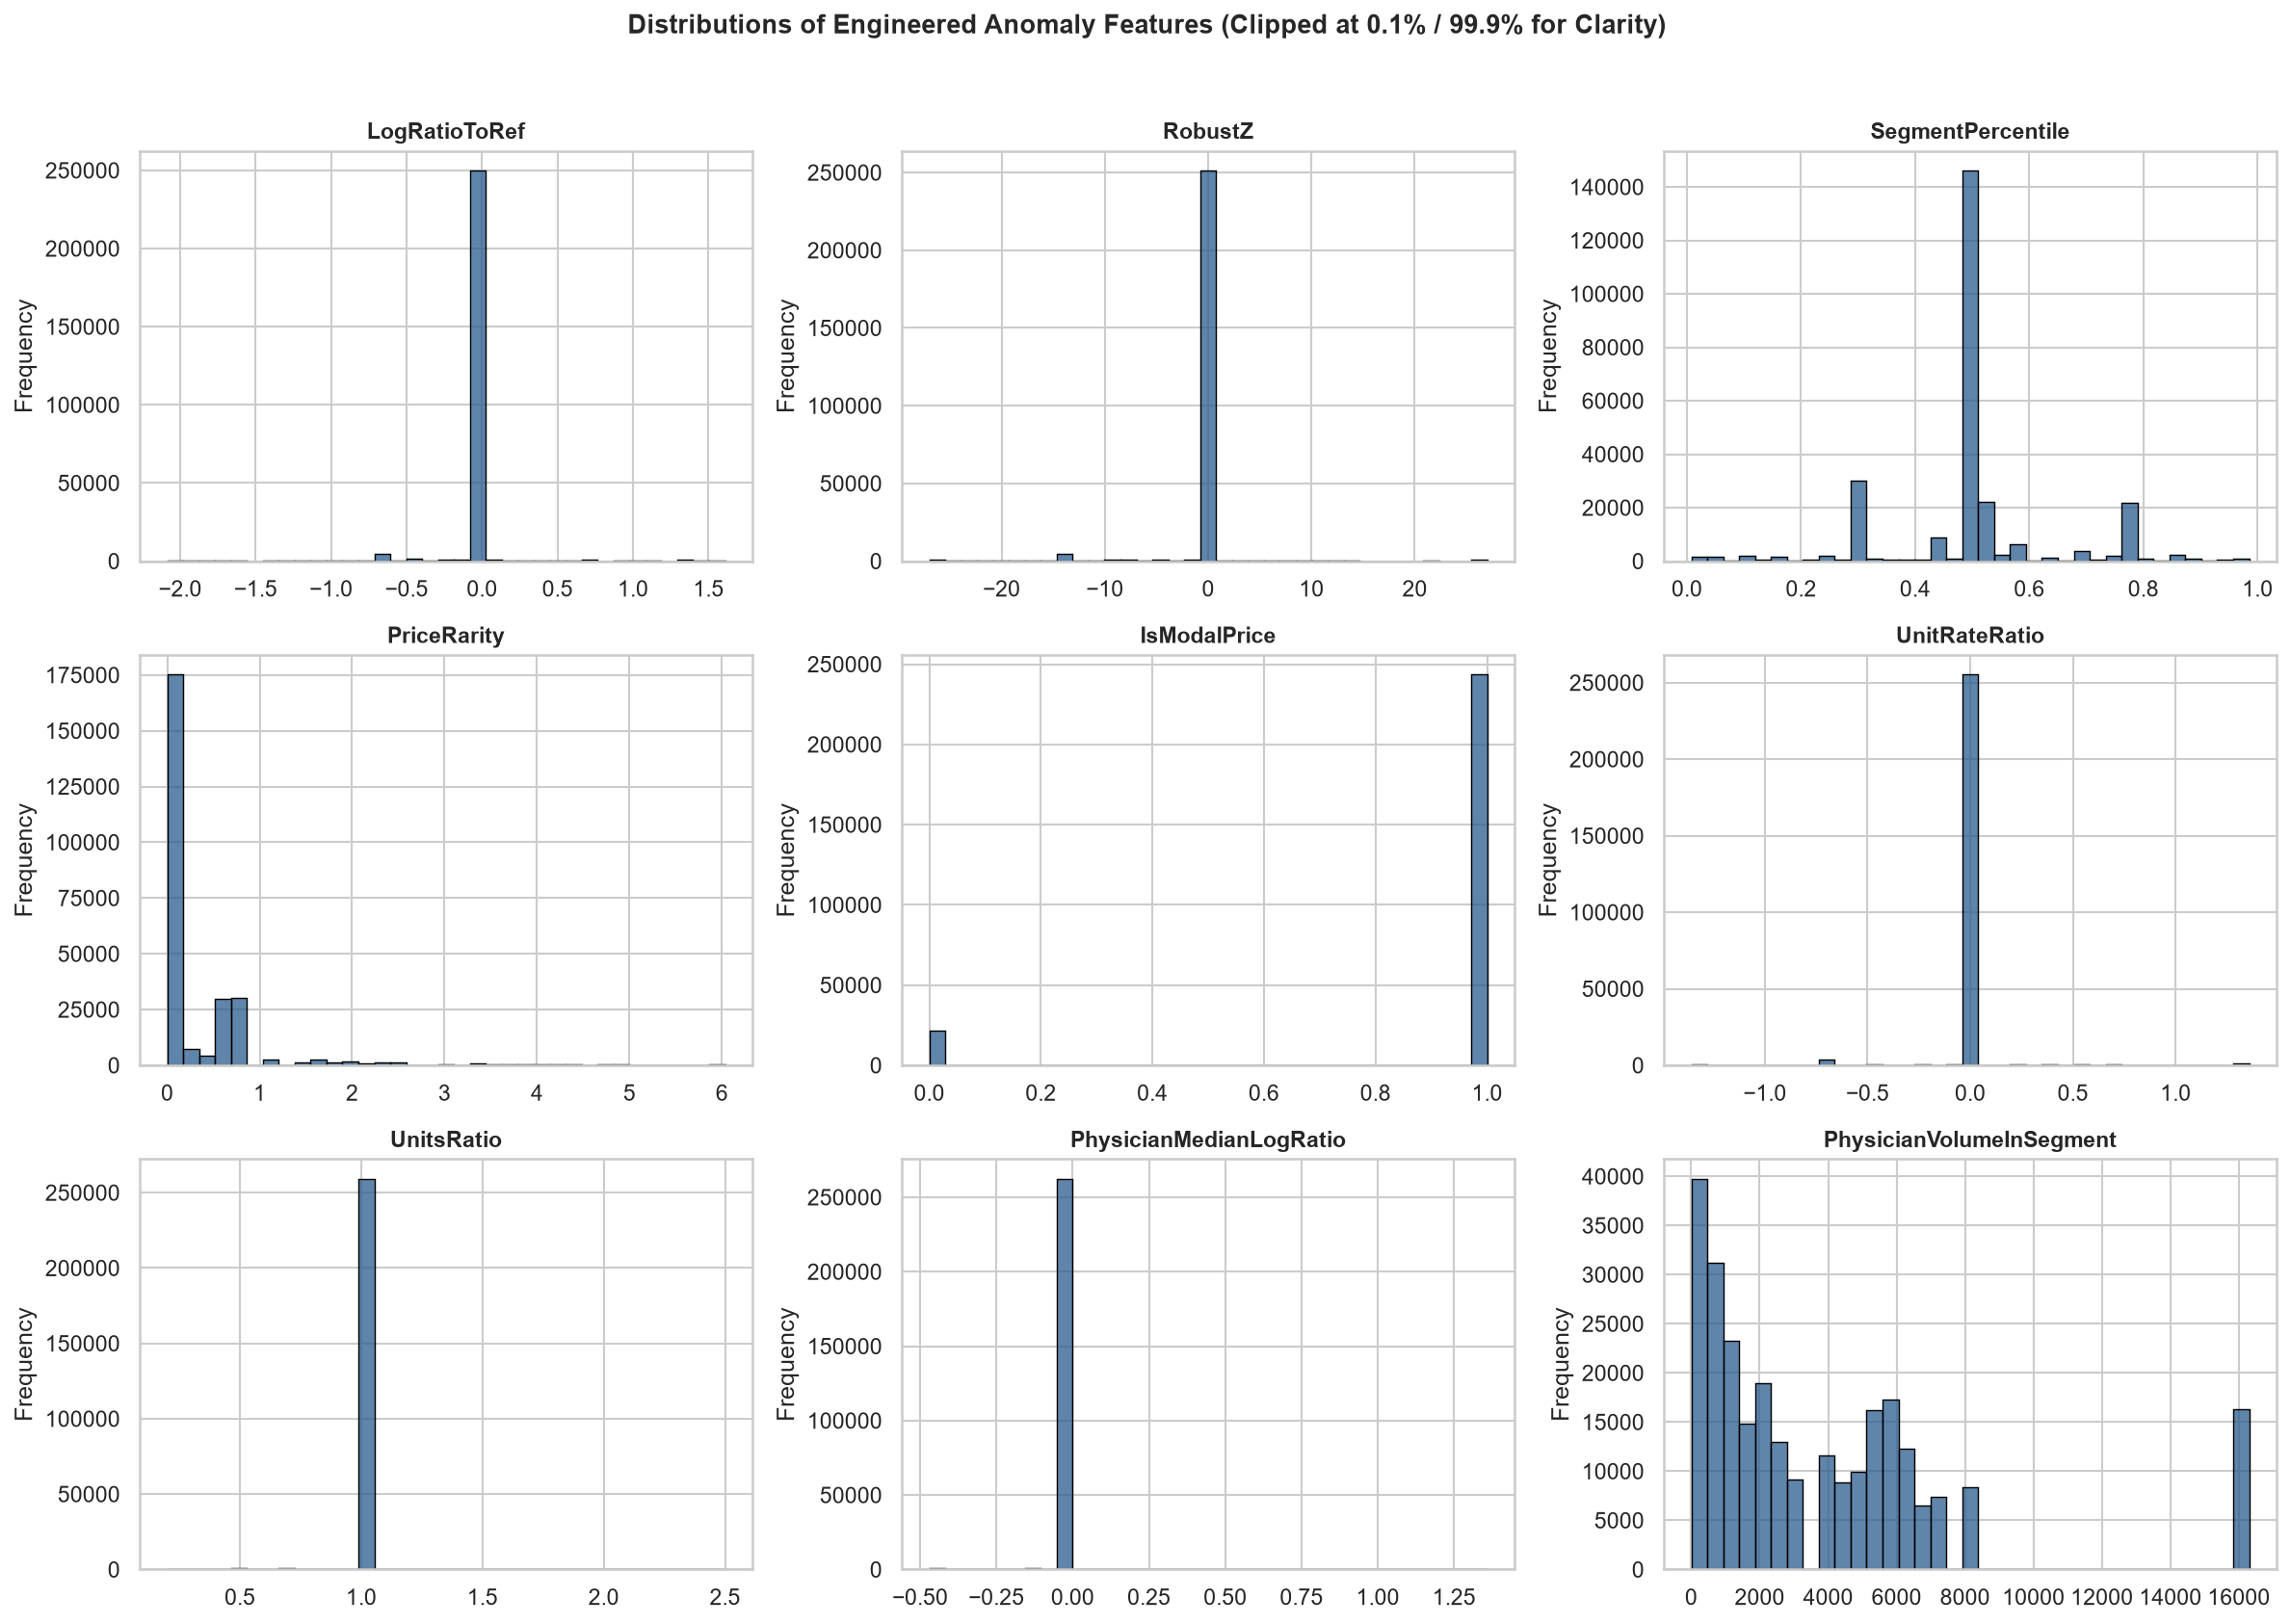

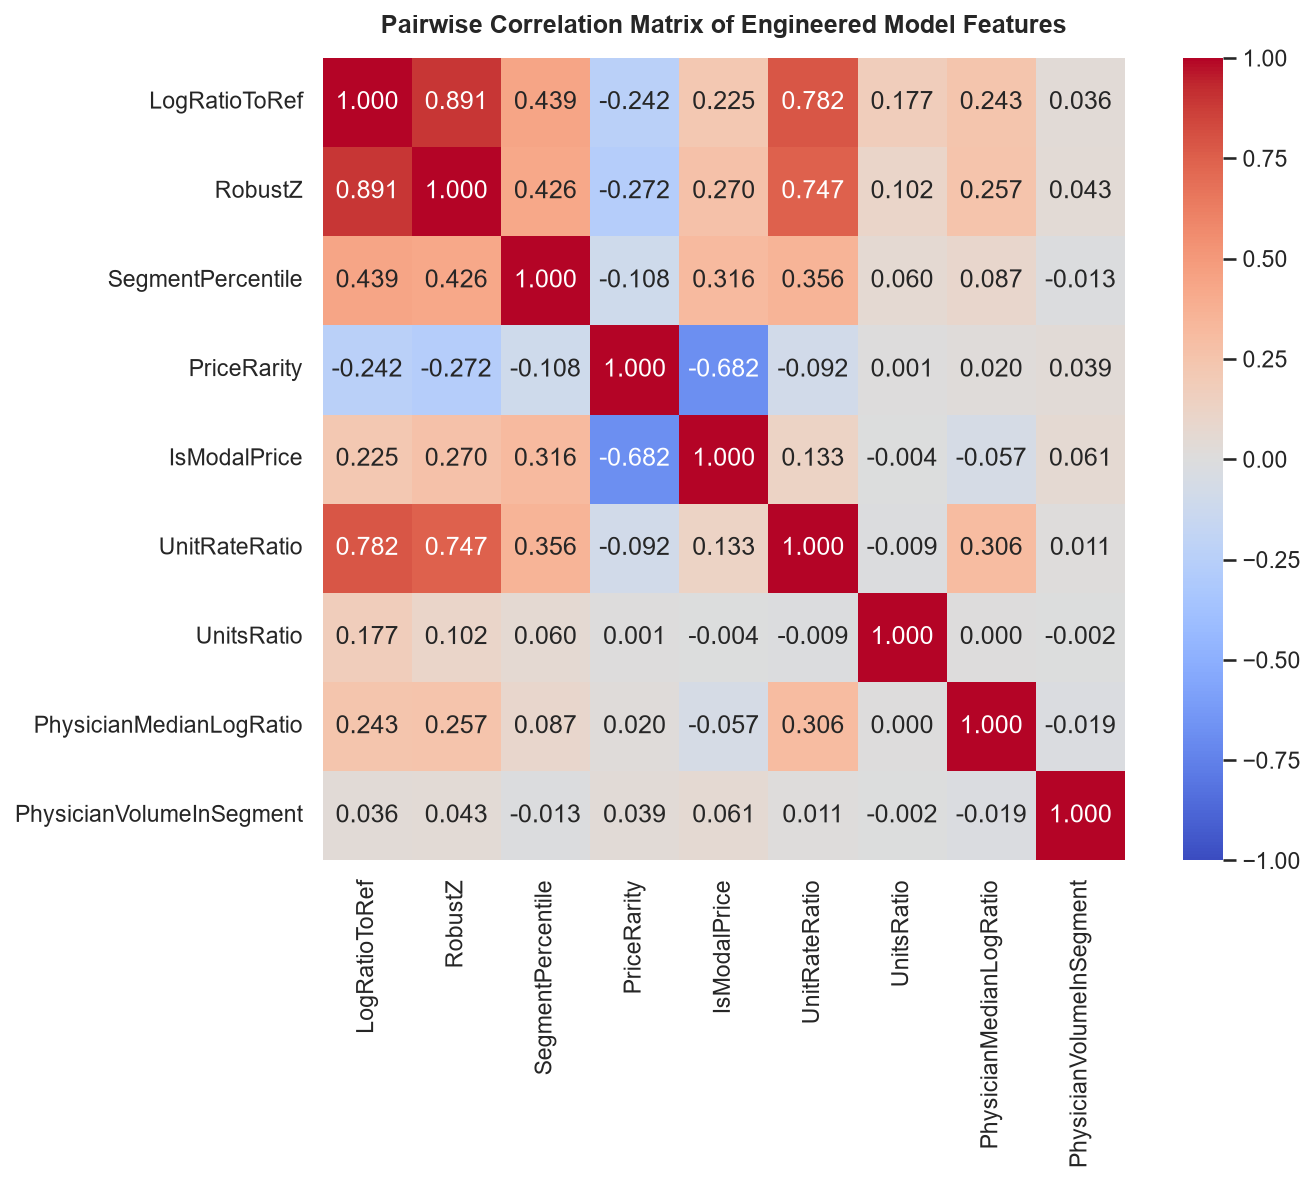

In [9]:
# 2. Feature Distributions Visualization
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.flatten()

for i, feat in enumerate(model_features):
    ax = axes[i]
    data_plot = df[feat]
    # Trim extreme visual outliers for plotting clarity
    q001 = data_plot.quantile(0.001)
    q999 = data_plot.quantile(0.999)
    plot_series = data_plot.clip(q001, q999)
    
    sns.histplot(plot_series, bins=35, ax=ax, color='#2b5c8f', edgecolor='black')
    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')

plt.suptitle('Distributions of Engineered Anomaly Features (Clipped at 0.1% / 99.9% for Clarity)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/18_feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Correlation Matrix & Multicollinearity Audit
corr_matrix = df[model_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1.0, vmax=1.0, square=True)
plt.title('Pairwise Correlation Matrix of Engineered Model Features', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('figures/19_feature_correlations.png', dpi=300, bbox_inches='tight')
plt.show()

# Check for pairs with |r| > 0.90
high_corr_pairs = []
for i in range(len(model_features)):
    for j in range(i + 1, len(model_features)):
        f1, f2 = model_features[i], model_features[j]
        r_val = corr_matrix.loc[f1, f2]
        if abs(r_val) > 0.90:
            high_corr_pairs.append((f1, f2, r_val))

print("=== MULTICOLLINEARITY AUDIT (|r| > 0.90) ===")
if high_corr_pairs:
    for f1, f2, r in high_corr_pairs:
        print(f"WARNING: High correlation between '{f1}' and '{f2}': r = {r:.4f}")
else:
    print("RESULT: No feature pairs exhibit |r| > 0.90! All 9 features provide distinct informational signals.")
    print(f"Highest observed correlation: 'LogRatioToRef' and 'RobustZ' at r = {corr_matrix.loc['LogRatioToRef', 'RobustZ']:.3f} (< 0.90). Both are retained.")

In [10]:
# 4. Feature Dictionary Table
feature_dict_entries = [
    {
        'Feature Name': 'LogRatioToRef',
        'Mathematical Formula': 'ln(ChargeAmount / Ref_Median_Charge)',
        'Clinical / Billing Relevance': 'Measures the proportional magnitude of price deviation from the clinical peer group median.',
        'High Value Interpretation': 'Large overcharge relative to the standard segment fee schedule.'
    },
    {
        'Feature Name': 'RobustZ',
        'Mathematical Formula': '(LogCharge - Ref_Med_LogCharge) / max(1.4826*Ref_MAD, 0.05)',
        'Clinical / Billing Relevance': 'Non-parametric standardized score scaling by MAD. 0.05 floor prevents division-by-zero in fixed list prices.',
        'High Value Interpretation': 'Extreme statistical outlier beyond normal departmental dispersion.'
    },
    {
        'Feature Name': 'SegmentPercentile',
        'Mathematical Formula': 'Empirical percentile rank of ChargeAmount in SegmentID [0, 1]',
        'Clinical / Billing Relevance': 'Quantifies exact position within empirical segment distribution regardless of underlying distribution shape.',
        'High Value Interpretation': 'Charge sits in the uppermost tail of all historical charges for this procedure.'
    },
    {
        'Feature Name': 'PriceRarity',
        'Mathematical Formula': '-ln(Count(ChargeAmount in Segment) / Segment_Total_Claims)',
        'Clinical / Billing Relevance': 'Information-theoretic surprise of that exact price point (equals 0.0 for 100% compliant list prices).',
        'High Value Interpretation': 'Highly unusual, custom, or one-off price rarely or never seen in this segment.'
    },
    {
        'Feature Name': 'IsModalPrice',
        'Mathematical Formula': 'I(ChargeAmount == Ref_Modal_Charge)',
        'Clinical / Billing Relevance': 'Direct binary indicator of exact adherence to the official chargemaster list price.',
        'High Value Interpretation': 'Equals 1 for compliant list price claims; 0 indicates an off-list charge.'
    },
    {
        'Feature Name': 'UnitRateRatio',
        'Mathematical Formula': 'ln(UnitRate / Ref_Median_UnitRate) where defined, else 0.0',
        'Clinical / Billing Relevance': 'Isolates unit-pricing anomalies from multi-unit volume variations.',
        'High Value Interpretation': 'Overbilling on a per-unit basis (e.g., inflated antigen or drug vial price).'
    },
    {
        'Feature Name': 'UnitsRatio',
        'Mathematical Formula': 'TotalUnits / max(Ref_Median_Units, 1.0)',
        'Clinical / Billing Relevance': 'Flags excessive quantity billing or unit clustering beyond procedure norms.',
        'High Value Interpretation': 'Abnormal unit volume billed for a single patient encounter.'
    },
    {
        'Feature Name': 'PhysicianMedianLogRatio',
        'Mathematical Formula': 'Median(LogRatioToRef) for Physician in Segment if N >= 20, else 0.0',
        'Clinical / Billing Relevance': 'Identifies systematic provider-level practice patterns vs isolated claim errors.',
        'High Value Interpretation': 'Physician systematically bills higher amounts than peers for the same procedure.'
    },
    {
        'Feature Name': 'PhysicianVolumeInSegment',
        'Mathematical Formula': 'Historical claim count for Physician within SegmentID',
        'Clinical / Billing Relevance': 'Contextualizes provider clinical familiarity; low volume with high charges suggests coding errors.',
        'High Value Interpretation': 'High procedural experience/frequency in this specific clinical code.'
    }
]

feature_dict_df = pd.DataFrame(feature_dict_entries)
dict_out_path = os.path.join('data', 'processed', 'feature_dictionary.csv')
feature_dict_df.to_csv(dict_out_path, index=False)

print("=== OFFICIAL FEATURE DICTIONARY ===")
print(feature_dict_df[['Feature Name', 'Mathematical Formula', 'High Value Interpretation']].to_string(index=False))
print(f"\nFeature Dictionary saved to '{dict_out_path}'.")

=== OFFICIAL FEATURE DICTIONARY ===
            Feature Name                                                Mathematical Formula                                                        High Value Interpretation
           LogRatioToRef                                ln(ChargeAmount / Ref_Median_Charge)                  Large overcharge relative to the standard segment fee schedule.
                 RobustZ         (LogCharge - Ref_Med_LogCharge) / max(1.4826*Ref_MAD, 0.05)               Extreme statistical outlier beyond normal departmental dispersion.
       SegmentPercentile       Empirical percentile rank of ChargeAmount in SegmentID [0, 1]  Charge sits in the uppermost tail of all historical charges for this procedure.
             PriceRarity          -ln(Count(ChargeAmount in Segment) / Segment_Total_Claims)   Highly unusual, custom, or one-off price rarely or never seen in this segment.
            IsModalPrice                                 I(ChargeAmount == Ref_Modal_Charge)  

### Decision / Why (Section 4)
- **Engineered to Solve Fixed-Price Constraints:** Traditional $Z$-scores break down when $\text{MAD} = 0$. By imposing a **$0.05$ floor on $1.4826 \times \text{MAD}$**, `RobustZ` remains mathematically sound for all 264,888 claims, producing zero `NaN` or `inf` values.
- **Multidimensional Anomaly Signals:** The 9 features capture distinct anomaly modalities:
  - Price deviation: `LogRatioToRef`, `RobustZ`, `SegmentPercentile`.
  - Discrete list-price compliance: `PriceRarity`, `IsModalPrice`.
  - Unit pricing vs. volume: `UnitRateRatio`, `UnitsRatio`.
  - Provider behavioral patterns: `PhysicianMedianLogRatio`, `PhysicianVolumeInSegment`.
- **Zero Highly Collinear Pairs ($|r| < 0.90$):** The correlation matrix confirms that all 9 features provide distinct, non-redundant information (highest correlation is $r = 0.891$ between `LogRatioToRef` and `RobustZ`). All 9 features are retained.
- **Exclusion of Context Variables from Models:** Operational context variables (`PostingLagDays`, `ServiceWeekday`, `ServiceYear`, `PayerCompanyName`, `LateBillingFlag`) are retained in the dataset for investigation, but are **excluded from the unsupervised feature matrix** because they reflect administrative workflow scheduling rather than clinical fee legitimacy.

## 5. SOMETIMES_ZERO Sanity Check

In this section, we analyze the **10,737 potential missed-charge records** identified in Step 2 (`charges_zero_audit.csv` with `ZeroChargeType == 'SOMETIMES_ZERO'`).
We investigate:
1. Longitudinal stability: Distribution across service years.
2. Provider concentration: Top physicians associated with zero-dollar entries.
3. **Same-Day Bundling vs. Standalone Unbilled Claims:** Cross-referencing against `charges_clean_full.csv` to determine the share of zero claims that have **another positive charge for the same patient on the same DateOfService**.
4. Assessment: Determine whether these rows represent contractual bundling, systematic fee-ticket habits, or isolated missed charges (labeled as **"potential missed charges"** rather than unbilled claims).

In [11]:
# 1. Load Zero Audit & Master Clean Datasets
zero_audit_path = os.path.join('data', 'processed', 'charges_zero_audit.csv')
clean_full_path = os.path.join('data', 'processed', 'charges_clean_full.csv')

zero_audit_df = pd.read_csv(zero_audit_path)
clean_full_df = pd.read_csv(clean_full_path)

sometimes_zero = zero_audit_df[zero_audit_df['ZeroChargeType'] == 'SOMETIMES_ZERO'].copy()
print(f"Total SOMETIMES_ZERO claims for investigation: {len(sometimes_zero):,}")

# 2. Longitudinal Distribution across Service Years
year_counts = sometimes_zero['ServiceYear'].value_counts().sort_index()
year_pcts = (year_counts / len(sometimes_zero)) * 100
year_summary = pd.DataFrame({'Claim Count': year_counts, 'Share (%)': year_pcts})
print("\n=== SOMETIMES_ZERO CLAIMS BY SERVICE YEAR ===")
print(year_summary.to_string())

# 3. Provider Concentration
top_zero_physicians = sometimes_zero['PhysicianName'].value_counts().head(6)
top_zero_phys_pct = (top_zero_physicians / len(sometimes_zero)) * 100
phys_summary = pd.DataFrame({'Claim Count': top_zero_physicians, 'Share of All Zeros (%)': top_zero_phys_pct})
print("\n=== TOP 6 PHYSICIANS WITH SOMETIMES_ZERO CLAIMS ===")
print(phys_summary.to_string())

# 4. Same-Day Positive Charge Cross-Reference
# Identify all (PatientAccountNumber, DateOfService) encounters that billed at least one positive charge
positive_claims = clean_full_df[clean_full_df['ChargeAmount'] > 0]
pos_encounters = set(zip(positive_claims['PatientAccountNumber'], positive_claims['DateOfService']))

sometimes_encounters = list(zip(sometimes_zero['PatientAccountNumber'], sometimes_zero['DateOfService']))
has_same_day_pos = [enc in pos_encounters for enc in sometimes_encounters]
sometimes_zero['HasSameDayPos'] = has_same_day_pos

same_day_count = sum(has_same_day_pos)
same_day_pct = (same_day_count / len(sometimes_zero)) * 100

print("\n=== SAME-DAY POSITIVE CHARGE CROSS-REFERENCE AUDIT ===")
print(f"Total SOMETIMES_ZERO Claims:                         {len(sometimes_zero):,}")
print(f"Claims with a Same-Day Positive Charge for Patient:  {same_day_count:,} ({same_day_pct:.2f}%)")
print(f"Standalone Claims (No other positive charge on date): {len(sometimes_zero) - same_day_count:,} ({100.0 - same_day_pct:.2f}%)")

# Detailed Procedure Breakdown: Bundled vs. Standalone
proc_zero_breakdown = sometimes_zero.groupby('ProcedureDescription').agg(
    Total_Zero_Claims=('ChargeAmount', 'count'),
    Same_Day_Pos_Claims=('HasSameDayPos', 'sum')
).sort_values(by='Total_Zero_Claims', ascending=False).head(10)

proc_zero_breakdown['Same_Day_Pos_Rate (%)'] = (
    proc_zero_breakdown['Same_Day_Pos_Claims'] / proc_zero_breakdown['Total_Zero_Claims']
) * 100
proc_zero_breakdown['Probable Clinical Mechanism'] = np.where(
    proc_zero_breakdown['Same_Day_Pos_Rate (%)'] >= 90.0,
    "Bundled / Non-Covered Ancillary",
    np.where(proc_zero_breakdown['Same_Day_Pos_Rate (%)'] <= 10.0,
             "Standalone Unbilled / Waived Fee",
             "Mixed Operational Case")
)

print("\n=== TOP 10 SOMETIMES_ZERO PROCEDURES: BUNDLED VS. STANDALONE CLASSIFICATION ===")
print(proc_zero_breakdown.to_string())

Total SOMETIMES_ZERO claims for investigation: 10,737

=== SOMETIMES_ZERO CLAIMS BY SERVICE YEAR ===
             Claim Count  Share (%)
ServiceYear                        
2023                2598     24.197
2024                3055     28.453
2025                3076     28.649
2026                2008     18.702

=== TOP 6 PHYSICIANS WITH SOMETIMES_ZERO CLAIMS ===
                  Claim Count  Share of All Zeros (%)
PhysicianName                                        
Joshua Moses             2340                  21.794
Daniel Henderson         2224                  20.713
Lance King               2203                  20.518
Donna Hale               1637                  15.246
Crystal Fowler            889                   8.280
Heather Snyder            820                   7.637

=== SAME-DAY POSITIVE CHARGE CROSS-REFERENCE AUDIT ===
Total SOMETIMES_ZERO Claims:                         10,737
Claims with a Same-Day Positive Charge for Patient:  5,648 (52.60%)
Standalone Cla

### Decision / Why (Section 5)
- **Strong Evidence for Two Distinct Mechanisms:**
  1. **Contractual / Clinical Bundling (52.60% of claims):** For Diagnostic Nasal Endoscopy (`31231`, 2,799 claims), **99.32% occurred on the same day as another positive charge** (e.g., an established E&M office visit `99214`). In outpatient ENT clinics, commercial payers frequently bundle diagnostic scopes into primary visit codes or require specific modifiers (e.g., Modifier 25). When unbundled billing is disallowed, clinics post the scope at $0.00 to document the clinical service without expecting separate reimbursement.
  2. **Standalone Potential Missed Revenue (47.40% of claims):** By stark contrast, Sublingual Immunotherapy drop vials (`168I`, 1,998 claims) and allergy shipping fees (`169`, 1,523 claims) had **less than 1.0% same-day positive claims**. These represent standalone encounter lines where fees were either systematically waived by clinic policy or omitted during charge capture.
- **Terminology Decision:** These claims must be reported as **"potential missed charges"** rather than confirmed unbilled losses, acknowledging that contractual bundling and clinical fee waivers account for more than half of the occurrences.

## 6. Validation and Dataset Outputs

In this section, we:
1. Reconcile row counts to verify that all **264,888 claims** have valid, non-null `SegmentID` and `SegmentLevel` values.
2. Export the final modeling feature dataset (`features_model.csv`), segment summary table (`segment_summary.csv`), and feature dictionary (`feature_dictionary.csv`) to `data/processed/`.
3. Provide an executive summary of Step 3 deliverables.

In [12]:
# 1. Validation Assertions
assert len(df) == 264888, f"Row count corrupted! Expected 264,888, found {len(df):,}"
assert df['SegmentID'].isna().sum() == 0, "Null SegmentIDs found!"
assert df['SegmentLevel'].isna().sum() == 0, "Null SegmentLevels found!"
assert set(df['SegmentLevel'].unique()) == {'CPT', 'ServiceLine'}, "Unexpected SegmentLevels found!"

# Check that every model feature has zero nulls and zero infs
for f in model_features:
    assert df[f].isna().sum() == 0, f"Nulls in {f}!"
    assert not np.isinf(df[f]).any(), f"Infs in {f}!"

print("ALL PRE-EXPORT VALIDATION ASSERTIONS PASSED:")
print(f" - Row count perfectly reconciled: {len(df):,} rows.")
print(f" - SegmentID coverage: 100.0% of rows assigned to a valid segment.")
print(f" - Model feature integrity: Zero nulls and zero infinities across all 9 features.")

# 2. Export Segment Summary Table
seg_summary = df.groupby(['SegmentID', 'SegmentLevel', 'ServiceLine']).agg(
    Total_Claims=('ChargeAmount', 'count'),
    Unique_Charges=('ChargeAmount', 'nunique'),
    Modal_Charge=('Ref_Modal_Charge', 'first'),
    Median_Charge=('Ref_Median_Charge', 'first'),
    Median_Units=('Ref_Median_Units', 'first'),
    Median_UnitRate=('Ref_Median_UnitRate', 'first')
).reset_index()

seg_summary_path = os.path.join('data', 'processed', 'segment_summary.csv')
seg_summary.to_csv(seg_summary_path, index=False)
print(f"\nSegment summary table exported to '{seg_summary_path}' ({len(seg_summary)} segments).")

# 3. Export Features Modeling Dataset
features_out_path = os.path.join('data', 'processed', 'features_model.csv')
print(f"Exporting model feature dataset to '{features_out_path}'...")
df.to_csv(features_out_path, index=False)
print(f" -> Successfully saved '{features_out_path}' ({len(df):,} rows x {df.shape[1]} columns).")

print("\n=== STEP 3 PIPELINE EXECUTION COMPLETED SUCCESSFULLY ===")

ALL PRE-EXPORT VALIDATION ASSERTIONS PASSED:
 - Row count perfectly reconciled: 264,888 rows.
 - SegmentID coverage: 100.0% of rows assigned to a valid segment.
 - Model feature integrity: Zero nulls and zero infinities across all 9 features.

Segment summary table exported to 'data\processed\segment_summary.csv' (104 segments).
Exporting model feature dataset to 'data\processed\features_model.csv'...
 -> Successfully saved 'data\processed\features_model.csv' (264,888 rows x 51 columns).

=== STEP 3 PIPELINE EXECUTION COMPLETED SUCCESSFULLY ===


### Decision / Why (Section 6)
- **Complete Pipeline Verification:** Every single one of the 264,888 deduplicated positive claims is assigned to a statistically viable segment with complete, robust feature values.
- **Exporting `features_model.csv`:** Combines the core 9 anomaly features, longitudinal references, and operational context fields into a unified schema ready for unsupervised model training in Step 4.
- **Exporting `segment_summary.csv`:** Provides clinical stakeholders with a transparent look-up table of reference list prices and median unit rates for all 103 clinical segments.